## D-optimality extrapolation grades

### Summary


Build an extrapolation scorer from a trained model and reference configurations
(`Configuration` objects, or a dataloader yielding them):

```python
from franken.rf.model import FrankenPotential
from franken.rf.extrapolation import ExtrapolationGrade

model = FrankenPotential.load("path/to/best_ckpt.pt", map_location="cpu")
extrapolation = ExtrapolationGrade.build_active_set(
    model, reference_configurations, selection_method="maxvol", per_species=True
)
extrapolation.save("extrapolation.pt")
```

`ExtrapolationGrade` owns the selected atomic feature rows, inverse factors, and
selection metadata. By default, it constructs a separate active set for each
chemical species; `per_species=False` constructs one shared set. MaxVol selects
up to a square set of informative rows, falling back to pivoted QR when there
are too few independent rows. `selection_method="pivoted-qr"` also allows an
explicit `max_rows` limit.

Pass the scorer or its saved path directly to the calculator:

```python
calculator = FrankenCalculator(
    model, device="cpu", extrapolation_grade="extrapolation.pt"
)
calculator.calculate(atoms, properties=["energy", "extrapolation_grade"])
grade = calculator.results["extrapolation_grade"]
atomic_grades = calculator.results["atomic_extrapolation"]
```

The structure grade is the maximum atomic grade. Each atomic grade is the
largest absolute coefficient expressing its feature row in the active set.
These are extrapolation indicators, not calibrated energy errors. Use a scorer
built with the same backbone, input scaler, and RF parameters as the model;
its file is stored separately from the model checkpoint. Extrapolation requires
the Python model and is not supported by exported TorchScript models.

For direct access, `model.atomic_feature_map(configuration)` returns raw atomic
RF rows after descriptor scaling and before pooling. At the RF-head level,
`model.rf.atomic_feature_map(scaled_descriptors)` provides the same operation.
The pooled feature map is the mean of these atomic rows within each structure.


### Train 

In [ ]:
! franken.autotune \
--dataset-name water-transfer \
--backbone=mace --mace.path-or-id "mace_mp/small" \
--rf=ms-gaussian --ms-gaussian.num-rf 512

atomic_energies: None
console_logging_level: INFO
dtype: float64
eval_splits: None
jac_chunk_size: auto
metrics: None
rf_normalization: leading_eig
run_dir: .
save_cholesky_factor: True
save_every_model: False
save_fmaps: False
scale_by_species: True
seed: 1337
backbone:
    family: mace
    interaction_block: 2
    path_or_id: mace_mp/small
best_model_selection:
    []
dataset:
    max_train_samples: 10
    name: water-transfer
    test_path: null
    train_path: null
    val_path: null
rfs:
    length_scale_high: 32.0
    length_scale_low: 4.0
    length_scale_num: 5
    num_random_features: 128
    rf_type: multiscale-gaussian
    rng_seed: 1337
    use_offset: 'True'
solver:
    energy_weight: 1.0
    force_weight:
      num: 7
      scale: log
      start: -2
      stop: 4
      value: null
      values: null
    l2_penalty:
      num: 6
      scale: log
      start: -11
      stop: -6
      value: null
      values: null
    stress_weight:
      num: 7
      scale: log
      star

### Load model

In [1]:
from franken.rf.model import FrankenPotential

model_folder = "run_261022_184239_2163307a/" #"run_261022_171508_2eb2f52b"

model = FrankenPotential.load(f"{model_folder}/best_ckpt.pt", map_location="cuda:0")

/home/lbonati@iit.local/software/miniforge3-mamba/envs/franken/lib/python3.13/site-packages/e3nn/o3/_wigner.py:10: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  _Jd, _W3j_flat, _W3j_indices = torch.load(os.path.join(os.path.dirname(__file__), 'constants.pt'))


cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.


### Load dataset

In [2]:
from franken.datasets import DATASET_REGISTRY
from franken.backbones.utils import CacheDir
train_path = DATASET_REGISTRY.get_path(
    name="water-transfer",
    split="train",
    base_path=CacheDir.get(),
)

from franken.data.dataset import FrankenAtomsDataset

train_dataset = FrankenAtomsDataset(
    data_path=train_path,
    split="train",
    gnn_config=model.gnn_config,
)

ASE -> Franken (train): 100%|██████████| 100/100 [00:00<00:00, 322.01it/s]


### Build active set

In [3]:
from franken.rf.extrapolation import ExtrapolationGrade

extrapolation = ExtrapolationGrade.build_active_set(
    model, 
    train_dataset, 
    selection_method="maxvol", 
    per_species=False,
    show_progress=True
)
extrapolation.save(f"{model_folder}/extrapolation.pt")

Selecting active rows (QR): 100%|██████████| 128/128 [00:00<00:00, 344.40it/s]
MaxVol: 23it [00:00, 244.23it/s]


In [5]:
# example of how to grade a configuration
configuration = train_dataset.__getitem__(0,no_targets=True).to("cuda:0")

extrapolation.grade_model_configuration(model, configuration)

tensor(1.0000, device='cuda:0', dtype=torch.float64)

### Grade validation set (with ASE calc)

In [6]:
from ase.io import read, write
from franken.calculators import FrankenCalculator

valid_path = DATASET_REGISTRY.get_path(
    name="water-transfer",
    split="val",
    base_path=CacheDir.get(),
)

valid_traj = read(valid_path, index=":")
calc = FrankenCalculator(model, 
                         extrapolation_grade=extrapolation # or path to extrapolation.pt
                         )

for atoms in valid_traj:
    calc.calculate(atoms, properties=["extrapolation_grade"])
    atoms.info["extrapolation_grade"] = calc.results["extrapolation_grade"]
    atoms.set_array("atomic_extrapolation", calc.results["atomic_extrapolation"])

write("valid_traj_with_extrapolation.extxyz", valid_traj)

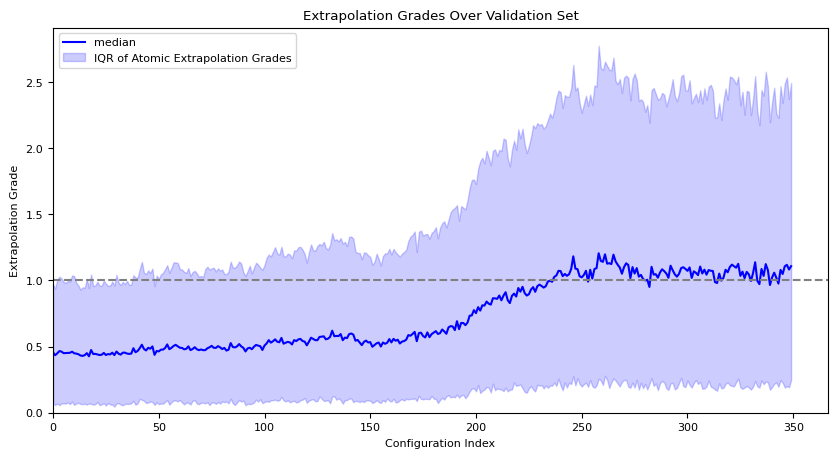

In [7]:
import matplotlib.pyplot as plt
import numpy as np

atomic_extrapolation_grades = np.array([atoms.get_array("atomic_extrapolation") for atoms in valid_traj])
max_extrapolation_grades = np.array([atoms.info["extrapolation_grade"] for atoms in valid_traj])
median_extrapolation_grades = np.array([np.median(atoms.get_array("atomic_extrapolation")) for atoms in valid_traj])
ci = np.percentile(atomic_extrapolation_grades, [25, 75], axis=1)

plt.figure(figsize=(10, 5))
plt.plot(median_extrapolation_grades, linestyle='-', color='b' , label = "median")
#plt.plot(max_extrapolation_grades, linestyle='-', color='r', label = "max")
plt.fill_between(range(len(median_extrapolation_grades)),
                 median_extrapolation_grades - np.array(ci[0]),
                 median_extrapolation_grades + np.array(ci[1]),
                 color='b', alpha=0.2, label='IQR of Atomic Extrapolation Grades')
plt.title("Extrapolation Grades Over Validation Set")
plt.xlabel("Configuration Index")
plt.ylabel("Extrapolation Grade")
plt.axhline(y=1.0, color='grey', linestyle='--')
plt.xlim(0,None)
plt.ylim(0,None)
#plt.yscale('log')
plt.legend()
plt.show()
